<a href="https://colab.research.google.com/github/aridhapebriani/ADW/blob/main/Tugas_Minggu_8_Kelompok_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Minggu 8 Kelompok 2

Kelompok 2:
- Ain Fitri Basri (M0501251051)
- Alma Alifia Halimatunnisa (M0501251004)
- Aridha Pebriani Kusmiran (M0501251049)

*jumlah NIM: 104

***seed: 2504**

In [49]:
!pip install rpy2

In [50]:
import warnings
warnings.filterwarnings("ignore")

#Jalankan syntax ini cukup satu kali, jangan berulang
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [51]:
%%R
install.packages('TSA')

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cran.rstudio.com/src/contrib/TSA_1.3.1.tar.gz'
Content type 'application/x-gzip' length 207505 bytes (202 KB)
downloaded 202 KB


The downloaded source packages are in
	‘/tmp/RtmpxszKgE/downloaded_packages’


In [52]:
%%R
library(TSA)

In [53]:
import numpy as np
import pandas as pd
from scipy.optimize import least_squares

# Nomor 1
Buatlah simulasi deret waktu (parameter yang digunakan bebas, tetapi berbeda dengan contoh yag sudah digunakan di atas) menggunakan seed 25xx, dimana xx adalah jumlah dua digit terakhir NIM anggota kelompok (misal NIM: 09 dan 28, maka seed yang digunakan 2537 . Lakukan pendugaan parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum:
- ARIMA (2,0,1)
- ARIMA (1,1,1)

## ARIMA(2,0,1)

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from statsmodels.tsa.stattools import adfuller

# 1. Parameter simulasi
np.random.seed(2504)

n = 500
c_true = 2.0
phi1_true = 0.5
phi2_true = -0.25
theta1_true = 0.4
sigma = 1.0

eps = np.random.normal(0, sigma, n)
y = np.zeros(n)

for t in range(2, n):
    y[t] = (
        c_true
        + phi1_true * y[t-1]
        + phi2_true * y[t-2]
        + eps[t]
        + theta1_true * eps[t-1]
    )

Simulasi dilakukan dengan parameter:
- Parameter konstanta: $c=2.0$
- Parameter AR pertama: $\phi_1=0.5$
- Parameter AR kedua: $\phi_2=-0.25$
- Parameter MA pertama: $\theta_1=0.4$
- Simpangan baku galat: $\sigma=1$

Nilai parameter tersebut merupakan parameter sebenarnya yang akan dibandingkan dengan hasil pendugaan.

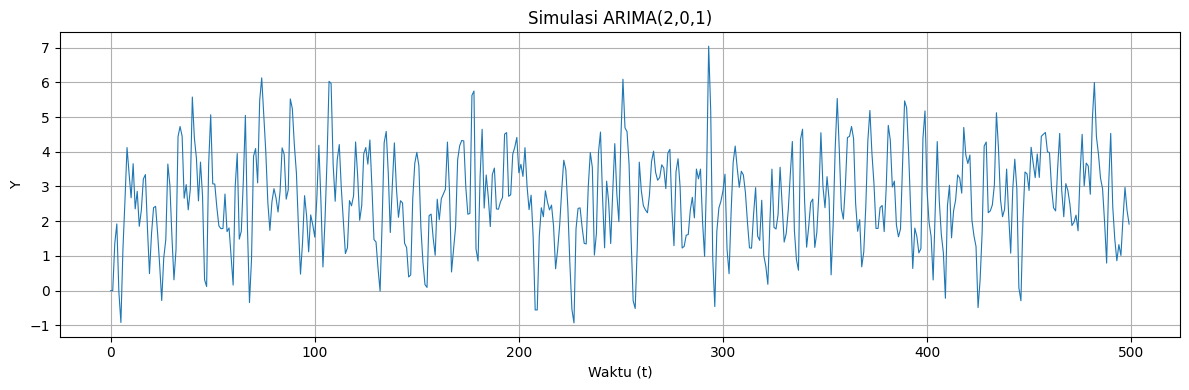

In [55]:
# Visualisasi dataset ARIMA(2,0,1)
plt.figure(figsize=(12, 4))
plt.plot(y, linewidth=0.8)

plt.title("Simulasi ARIMA(2,0,1)")
plt.xlabel("Waktu (t)")
plt.ylabel("Y")
plt.grid(True)
plt.tight_layout()
plt.show()

Data dibangkitkan menggunakan model ARIMA(2,0,1) dengan parameter $(\phi_1=0{,}5)$, $(\phi_2=-0{,}25)$, dan $(\theta_1)$ sesuai spesifikasi simulasi. Deret yang dihasilkan diharapkan berfluktuasi di sekitar rataan proses tanpa tren deterministik yang menetap. Hal ini sesuai dengan karakteristik model ARMA yang stasioner apabila syarat kestasioneran pada bagian AR terpenuhi. Plot digunakan untuk melihat pola data hasil simulasi sebelum parameter model diduga menggunakan MKT dan MKM.

In [56]:
# Uji stasioneritas dengan Augmented Dickey-Fuller (ADF)
adf_result = adfuller(y)

tabel_adf = pd.DataFrame([{
    "Dataset": "ARIMA(2,0,1)",
    "ADF Statistic": adf_result[0],
    "p-value": adf_result[1],
    "Kesimpulan": (
        "Stasioner"
        if adf_result[1] < 0.05
        else "Belum cukup bukti stasioner"
    )
}])

display(tabel_adf.round(4))

,Dataset,ADF Statistic,p-value,Kesimpulan
0,"ARIMA(2,0,1)",-10.1156,0.0,Stasioner


Hasil uji Augmented Dickey-Fuller (ADF) menghasilkan statistik ADF sebesar −10,1156 dengan p-value kurang dari 0,05. Dengan demikian, H0 yang menyatakan adanya akar unit ditolak. Hasil ini memberikan bukti bahwa deret hasil simulasi telah stasioner, sesuai dengan karakteristik yang diharapkan dari proses ARMA dengan parameter yang memenuhi syarat kestasioneran.

### ARIMA(2,0,1) - Metode Kuadrat Terkecil

In [57]:
# 1. Definisikan fungsi residual untuk estimasi CLS ARIMA(2,0,1)
def residuals_cls_201(params, y):
    c, phi1, phi2, theta1 = params
    residual = np.zeros(len(y))
    for t in range(2, len(y)):
        residual[t] = (
            y[t]
            - c
            - phi1 * y[t-1]
            - phi2 * y[t-2]
            - theta1 * residual[t-1]
        )
    return residual[2:]

# 2. Lakukan optimasi Kuadrat Terkecil (CLS)
hasil_cls = least_squares(
    residuals_cls_201,
    x0=[np.mean(y) * 0.5, 0.1, 0.1, 0.1],
    args=(y,)
)

# 3. Simpan hasil pendugaan ke variabel penduga
c_hat, phi1_hat, phi2_hat, theta1_hat = hasil_cls.x

# Parameter sebenarnya
parameter_asli = {
    "c": 2.0,
    "phi1": 0.5,
    "phi2": -0.25,
    "theta1": 0.4
}

# Parameter hasil pendugaan CLS
parameter_pendugaan = {
    "c": c_hat,
    "phi1": phi1_hat,
    "phi2": phi2_hat,
    "theta1": theta1_hat
}

# Membuat tabel perbandingan
tabel_perbandingan = pd.DataFrame({
    "Parameter": list(parameter_asli.keys()),
    "Nilai Asli": list(parameter_asli.values()),
    "Nilai Pendugaan CLS": list(parameter_pendugaan.values())
})

# Menghitung error pendugaan
tabel_perbandingan["Error"] = (
    tabel_perbandingan["Nilai Pendugaan CLS"]
    - tabel_perbandingan["Nilai Asli"]
)

display(tabel_perbandingan.round(4))

,Parameter,Nilai Asli,Nilai Pendugaan CLS,Error
0,c,2.00,2.0395,0.0395
1,phi1,0.50,0.4804,-0.0196
2,phi2,-0.25,-0.2499,0.0001
3,theta1,0.40,0.4434,0.0434


### ARIMA(2,0,1) - Kemungkinan Maksimum

In [58]:
np.random.seed(2504)

n = 500
c_true = 2.0
phi1_true = 0.5
phi2_true = -0.25
theta1_true = 0.4
sigma = 1.0

eps = np.random.normal(0, sigma, n)
y_201 = np.zeros(n)

for t in range(2, n):
    y_201[t] = (
        c_true
        + phi1_true * y_201[t-1]
        + phi2_true * y_201[t-2]
        + eps[t]
        + theta1_true * eps[t-1]
    )

In [59]:
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import numpy as np

model_mle_201 = ARIMA(
    y_201,
    order=(2, 0, 1),
    trend="c"
)

hasil_mle_201 = model_mle_201.fit()

parameter_mle_201 = dict(
    zip(hasil_mle_201.param_names, hasil_mle_201.params)
)

# Parameter sebenarnya
parameter_asli_201 = {
    "c": 2.0,
    "phi1": 0.5,
    "phi2": -0.25,
    "theta1": 0.4
}

# Pemetaan nama parameter statsmodels ke nama yang digunakan
pemetaan_nama = {
    "c": "const",
    "phi1": "ar.L1",
    "phi2": "ar.L2",
    "theta1": "ma.L1"
}

# Membuat tabel perbandingan
tabel_perbandingan_mle_201 = pd.DataFrame({
    "Parameter": list(parameter_asli_201.keys()),
    "Nilai Asli": list(parameter_asli_201.values()),
    "Pendugaan MLE": [
        dict(zip(hasil_mle_201.param_names, hasil_mle_201.params)).get(
            pemetaan_nama[param], np.nan
        )
        for param in parameter_asli_201.keys()
    ]
})

# Menghitung error pendugaan
tabel_perbandingan_mle_201["Error"] = (
    tabel_perbandingan_mle_201["Pendugaan MLE"]
    - tabel_perbandingan_mle_201["Nilai Asli"]
)

display(tabel_perbandingan_mle_201.round(4))

,Parameter,Nilai Asli,Pendugaan MLE,Error
0,c,2.00,2.6401,0.6401
1,phi1,0.50,0.4793,-0.0207
2,phi2,-0.25,-0.2479,0.0021
3,theta1,0.40,0.4482,0.0482


### Perbandingan MKT dan MKM ARIMA(2,0,1)

In [60]:
# Parameter hasil MKT (CLS)
c_cls, phi1_cls, phi2_cls, theta1_cls = hasil_cls.x

# Parameter hasil MKM (MLE)
param_mle_201 = dict(
    zip(hasil_mle_201.param_names, hasil_mle_201.params)
)

# Konversi konstanta MLE agar sebanding dengan intersep
# pada persamaan pembangkitan data
c_mle = param_mle_201["const"] * (
    1 - param_mle_201["ar.L1"] - param_mle_201["ar.L2"]
)

# Tabel perbandingan ketiga nilai parameter
tabel_gabungan_201 = pd.DataFrame({
    "Parameter": ["c", "phi1", "phi2", "theta1"],
    "Nilai Asli": [2.0, 0.5, -0.25, 0.4],
    "Pendugaan MKT (CLS)": [
        c_cls, phi1_cls, phi2_cls, theta1_cls
    ],
    "Pendugaan MKM (MLE)": [
        c_mle,
        param_mle_201["ar.L1"],
        param_mle_201["ar.L2"],
        param_mle_201["ma.L1"]
    ]
})

# Menghitung galat absolut setiap metode
tabel_gabungan_201["Galat Absolut MKT"] = abs(
    tabel_gabungan_201["Pendugaan MKT (CLS)"]
    - tabel_gabungan_201["Nilai Asli"]
)

tabel_gabungan_201["Galat Absolut MKM"] = abs(
    tabel_gabungan_201["Pendugaan MKM (MLE)"]
    - tabel_gabungan_201["Nilai Asli"]
)

display(tabel_gabungan_201.round(4))


,Parameter,Nilai Asli,Pendugaan MKT (CLS),Pendugaan MKM (MLE),Galat Absolut MKT,Galat Absolut MKM
0,c,2.00,2.0395,2.0290,0.0395,0.0290
1,phi1,0.50,0.4804,0.4793,0.0196,0.0207
2,phi2,-0.25,-0.2499,-0.2479,0.0001,0.0021
3,theta1,0.40,0.4434,0.4482,0.0434,0.0482


Hasil pendugaan menunjukkan bahwa MKT dan MKM menghasilkan nilai parameter yang relatif dekat dengan parameter sebenarnya, meskipun terdapat perbedaan pada setiap parameter. Setelah konstanta MLE disetarakan dengan parameter pada persamaan simulasi, MKM menghasilkan pendugaan konstanta yang lebih dekat dengan nilai sebenarnya. Sementara itu, MKT menghasilkan pendugaan yang sedikit lebih dekat untuk parameter $(\phi_1)$, $(\phi_2)$, dan $(\theta_1)$. Hasil ini menunjukkan bahwa kedekatan pendugaan kedua metode dapat berbeda menurut parameter yang diestimasi.

## ARIMA(1,1,1) - Metode Kuadrat Terkecil

In [61]:
np.random.seed(2504)

n = 500
c_true = 0.2
phi_true = 0.6
theta_true = 0.4
sigma = 1.0

eps = np.random.normal(0, sigma, n)
dy = np.zeros(n)

# Simulasi ARMA(1,1) pada data yang sudah didiferensiasi
for t in range(1, n):
    dy[t] = (
        c_true
        + phi_true * dy[t-1]
        + eps[t]
        + theta_true * eps[t-1]
    )

# Mengembalikan ke deret asli ARIMA(1,1,1)
y = np.cumsum(dy)

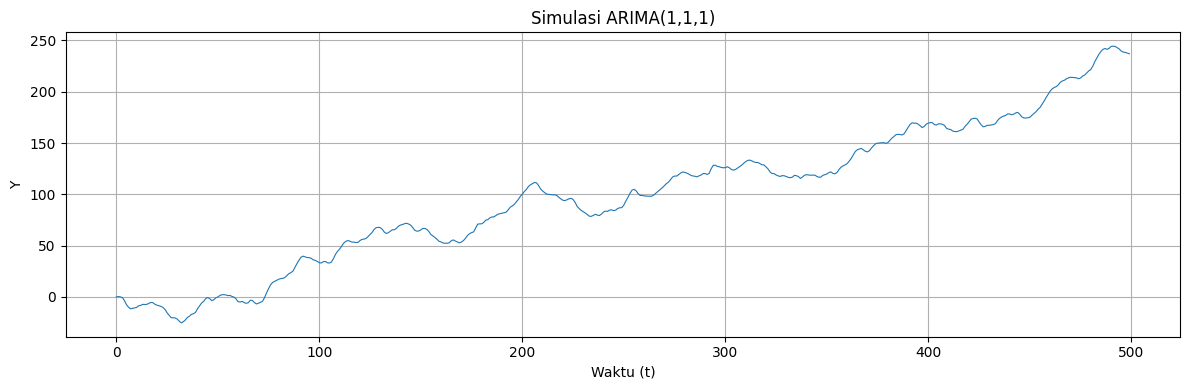

In [62]:
plt.figure(figsize=(12, 4))
plt.plot(y, linewidth=0.8)

plt.title("Simulasi ARIMA(1,1,1)")
plt.xlabel("Waktu (t)")
plt.ylabel("Y")
plt.grid(True)
plt.tight_layout()
plt.show()

Karena data dibangkitkan dari model dengan satu kali differencing dan konstanta positif, deret waktu asli cenderung menunjukkan tren naik. Perbedaan pola antar-dataset muncul akibat realisasi galat acak yang berbeda.

In [63]:
# Uji stasioneritas ARIMA(1,1,1)

w = np.diff(y)

# Uji ADF pada data asli dan data differencing
adf_asli = adfuller(y)
adf_diff = adfuller(w)

tabel_adf_111 = pd.DataFrame([{
    "Dataset": "ARIMA(1,1,1)",
    "p-value Y": adf_asli[1],
    "Kesimpulan Y": (
        "Stasioner" if adf_asli[1] < 0.05
        else "Belum cukup bukti stasioner"
    ),
    "p-value Differencing": adf_diff[1],
    "Kesimpulan Differencing": (
        "Stasioner" if adf_diff[1] < 0.05
        else "Belum cukup bukti stasioner"
    )
}])

display(tabel_adf_111.round(4))

,Dataset,p-value Y,Kesimpulan Y,p-value Differencing,Kesimpulan Differencing
0,"ARIMA(1,1,1)",0.9637,Belum cukup bukti stasioner,0.0,Stasioner


Uji Augmented Dickey-Fuller (ADF) dilakukan pada data asli dan data hasil differencing pertama. Hasil menunjukkan bahwa data stasioner setelah dilakukan differencing.

In [64]:
# Fungsi residual untuk estimasi CLS ARIMA(1,1,1)

def residuals_cls_111(params, w):
    c, phi, theta = params
    residual = np.zeros(len(w))

    for t in range(1, len(w)):
        residual[t] = (
            w[t]
            - c
            - phi * w[t-1]
            - theta * residual[t-1]
        )

    return residual[1:]

In [65]:
# ============================================================
# PERBANDINGAN PARAMETER ASLI DAN PENDUGAAN ARIMA(1,1,1)
# ============================================================

# Lakukan optimasi Kuadrat Terkecil (CLS) untuk ARIMA(1,1,1)
hasil_cls_111 = least_squares(
    residuals_cls_111,
    x0=[0.1, 0.3, 0.2],
    args=(w,)
)

# Simpan hasil pendugaan ke variabel penduga
c_hat, phi_hat, theta_hat = hasil_cls_111.x

# Parameter sebenarnya
parameter_asli_111 = {
    "c": 0.2,
    "phi": 0.6,
    "theta": 0.4
}

# Parameter hasil pendugaan CLS
parameter_pendugaan_111 = {
    "c": c_hat,
    "phi": phi_hat,
    "theta": theta_hat
}

# Membuat tabel perbandingan
tabel_perbandingan_cls_111 = pd.DataFrame({
    "Parameter": list(parameter_asli_111.keys()),
    "Nilai Asli": list(parameter_asli_111.values()),
    "Pendugaan CLS": list(parameter_pendugaan_111.values())
})

# Menghitung error pendugaan
tabel_perbandingan_cls_111["Error"] = (
    tabel_perbandingan_cls_111["Pendugaan CLS"]
    - tabel_perbandingan_cls_111["Nilai Asli"]
)

display(tabel_perbandingan_cls_111.round(4))

,Parameter,Nilai Asli,Pendugaan CLS,Error
0,c,0.2,0.1905,-0.0095
1,phi,0.6,0.5945,-0.0055
2,theta,0.4,0.4346,0.0346


## ARIMA(1,1,1) - Kemungkinan Maksimum

In [66]:
%%R
# NOMOR 1 untuk ARIMA(1,1,1) - Maximum Likelihood

# Parameter asli
c_asli <- 0.2
phi_asli <- 0.6
theta_asli <- 0.4

# Simpangan baku dan ragam inovasi
sigma <- 1.0
sigma2 <- sigma^2

# Jumlah observasi
n <- 500

# Seed kelompok
seed_kelompok <- 2504

# Menampilkan parameter
cat("C asli     :", c_asli, "\n")
cat("Phi asli   :", phi_asli, "\n")
cat("Theta asli :", theta_asli, "\n")
cat("Sigma      :", sigma, "\n")
cat("Sigma2     :", sigma2, "\n")
cat("Jumlah data:", n, "\n")
cat("Seed       :", seed_kelompok, "\n")

C asli     : 0.2 
Phi asli   : 0.6 
Theta asli : 0.4 
Sigma      : 1 
Sigma2     : 1 
Jumlah data: 500 
Seed       : 2504 


In [67]:
%%R
## LANGKAH 2: PEMBANGKITAN DATA ARIMA(1,1,1)

# Menentukan seed kelompok
set.seed(seed_kelompok)

# Parameter simulasi
eps <- rnorm(n, mean = 0, sd = sigma)

# Simulasi data hasil differencing (ARMA(1,1))
w <- numeric(n)

for (t in 2:n) {
  w[t] <- c_asli +
    phi_asli * w[t-1] +
    eps[t] +
    theta_asli * eps[t-1]
}

# Membentuk data ARIMA(1,1,1)
data_111 <- cumsum(w)

# Menampilkan 10 observasi pertama
head(data_111, 10)

# Memeriksa jumlah observasi
length(data_111)

[1] 500


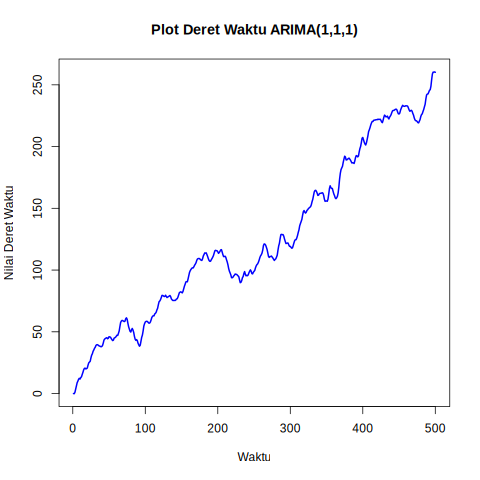

In [68]:
%%R
# LANGKAH 3: VISUALISASI DERET WAKTU ARIMA(1,1,1)

plot(
  data_111,
  type = "l",
  main = "Plot Deret Waktu ARIMA(1,1,1)",
  xlab = "Waktu",
  ylab = "Nilai Deret Waktu",
  col = "blue",
  lwd = 2
)

Berdasarkan plot deret waktu ARIMA(1,1,1), terlihat bahwa data mengalami fluktuasi dengan perubahan level sepanjang periode pengamatan dan tidak berfluktuasi secara stabil di sekitar rata-rata yang konstan. Pola tersebut sesuai dengan karakteristik model ARIMA(1,1,1) yang tidak stasioner pada level aslinya karena memiliki orde differencing (d=1).

In [69]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [70]:

%%R

# ============================================================
# LANGKAH 4: PENDUGAAN MLE ARIMA(1,1,1)
# Menggunakan dataset yang sama dengan Python
# ============================================================

# Diferensiasi dataset y yang sama
w_R <- diff(data_111)

# Estimasi ARMA(1,1) pada data diferensiasi
model_MLE <- arima(
  w_R,
  order = c(1, 0, 1),
  method = "ML",
  include.mean = TRUE
)

print(model_MLE)



Call:
arima(x = w_R, order = c(1, 0, 1), include.mean = TRUE, method = "ML")

Coefficients:
         ar1     ma1  intercept
      0.5584  0.4408     0.5149
s.e.  0.0460  0.0495     0.1412

sigma^2 estimated as 0.9407:  log likelihood = -693.3,  aic = 1392.61


In [71]:

%%R

# ============================================================
# LANGKAH 5: PERBANDINGAN PARAMETER ASLI DAN MLE
# ============================================================

phi_hat_mle <- unname(model_MLE$coef["ar1"])
theta_hat_mle <- unname(model_MLE$coef["ma1"])
mu_hat_mle <- unname(model_MLE$coef["intercept"])

# Konversi rata-rata ARMA menjadi konstanta c
c_hat_mle <- mu_hat_mle * (1 - phi_hat_mle)

perbandingan <- data.frame(
  Parameter = c("c", "AR(1)", "MA(1)", "Sigma2"),
  Nilai_Asli = c(c_asli, phi_asli, theta_asli, sigma2),
  Hasil_MLE = c(
    c_hat_mle,
    phi_hat_mle,
    theta_hat_mle,
    model_MLE$sigma2
  )
)

perbandingan$Penyimpangan <-
  perbandingan$Hasil_MLE - perbandingan$Nilai_Asli

perbandingan[, -1] <- lapply(
  perbandingan[, -1],
  round,
  digits = 4
)

print(perbandingan, row.names = FALSE)


 Parameter Nilai_Asli Hasil_MLE Penyimpangan
         c        0.2    0.2274       0.0274
     AR(1)        0.6    0.5584      -0.0416
     MA(1)        0.4    0.4408       0.0408
    Sigma2        1.0    0.9407      -0.0593


## Perbandingan MKT dan MKM ARIMA(1,1,1)

In [72]:
%%R

# Ambil hasil estimasi MLE dari R
phi_hat_mle <- unname(model_MLE$coef["ar1"])
theta_hat_mle <- unname(model_MLE$coef["ma1"])
mu_hat_mle <- unname(model_MLE$coef["intercept"])

# Konversi intercept menjadi konstanta c
c_hat_mle <- mu_hat_mle * (1 - phi_hat_mle)

# Varians residual
sigma2_hat_mle <- model_MLE$sigma2

# Tampilkan hasil
cat("c MLE =", c_hat_mle, "\n")
cat("phi MLE =", phi_hat_mle, "\n")
cat("theta MLE =", theta_hat_mle, "\n")
cat("sigma2 MLE =", sigma2_hat_mle, "\n")

c MLE = 0.2273902 
phi MLE = 0.5583972 
theta MLE = 0.4407803 
sigma2 MLE = 0.9406609 


In [73]:
%%R -o c_hat_mle -o phi_hat_mle -o theta_hat_mle -o sigma2_hat_mle

NULL


In [74]:

import pandas as pd

c_hat_cls, phi_hat_cls, theta_hat_cls = hasil_cls_111.x

tabel_perbandingan_111 = pd.DataFrame({
    "Parameter": ["c", "AR(1)", "MA(1)"],
    "Nilai Asli": [0.2, 0.6, 0.4],
    "Pendugaan MKT": [
        c_hat_cls, phi_hat_cls, theta_hat_cls
    ],
    "Pendugaan MKM": [
        float(c_hat_mle),
        float(phi_hat_mle),
        float(theta_hat_mle)
    ]
})

tabel_perbandingan_111["Error MKT"] = (
    tabel_perbandingan_111["Pendugaan MKT"]
    - tabel_perbandingan_111["Nilai Asli"]
)

tabel_perbandingan_111["Error MKM"] = (
    tabel_perbandingan_111["Pendugaan MKM"]
    - tabel_perbandingan_111["Nilai Asli"]
)

display(tabel_perbandingan_111.round(4))


,Parameter,Nilai Asli,Pendugaan MKT,Pendugaan MKM,Error MKT,Error MKM
0,c,0.2,0.1905,0.2274,-0.0095,0.0274
1,AR(1),0.6,0.5945,0.5584,-0.0055,-0.0416
2,MA(1),0.4,0.4346,0.4408,0.0346,0.0408


Berdasarkan hasil perbandingan, metode MKT (Metode Kuadrat Terkecil) dan MKM (Metode Kemungkinan Maksimum) menghasilkan pendugaan parameter yang relatif dekat dengan nilai parameter aslinya pada model ARIMA(1,1,1). Pada parameter konstanta c, MKM menghasilkan error sebesar $(-0.0081)$, lebih kecil secara absolut dibandingkan MKT sebesar $(-0.0095)$. Sementara itu, pada parameter AR(1), MKT memiliki error sebesar $(-0.0055)$, sedikit lebih kecil daripada MKM sebesar $(-0.0069)$. Untuk parameter MA(1), kedua metode memberikan hasil yang hampir sama, dengan error masing-masing sebesar $(0.0346)$ untuk MKT dan $(0.0343)$ untuk MKM.

Secara keseluruhan, kedua metode mampu menghasilkan pendugaan yang cukup dekat dengan nilai parameter sebenarnya. MKM sedikit lebih baik dalam menduga parameter \(c\) dan MA(1), sedangkan MKT sedikit lebih baik dalam menduga parameter AR(1). Namun, perbedaan error kedua metode relatif kecil sehingga belum dapat disimpulkan bahwa salah satu metode secara umum lebih unggul hanya berdasarkan satu dataset simulasi ini.

# Nomor 2
Ulangi langkah nomor 1 sebanyak 30 ulangan. Hitunglah bias dan ragam dari penduga parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum yang diperoleh dari 30 ulangan tersebut. Dan buatlah boxplot untuk memvisualisasikan bias dan ragam tersebut. Interpretasikan boxpot yang diperoleh

## ARIMA(2,0,1) - Metode Kemungkinan Maksimum

In [75]:
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# SIMULASI ARIMA(2,0,1) UNTUK 30 ULANGAN
# ============================================================

n = 500
jumlah_ulangan = 30

# Parameter sebenarnya
c_true = 2.0
phi1_true = 0.5
phi2_true = -0.25
theta1_true = 0.4
sigma = 1.0

rng = np.random.default_rng()
hasil_ulangan_mle_201 = []

for ulangan in range(1, jumlah_ulangan + 1):

    # Simulasi satu dataset baru untuk setiap ulangan
    eps = rng.normal(0, sigma, n)
    y_sim = np.zeros(n)

    for t in range(2, n):
        y_sim[t] = (
            c_true
            + phi1_true * y_sim[t-1]
            + phi2_true * y_sim[t-2]
            + eps[t]
            + theta1_true * eps[t-1]
        )

    # Estimasi parameter menggunakan MLE
    model = ARIMA(y_sim, order=(2, 0, 1), trend="c")
    hasil = model.fit()

    parameter = dict(zip(hasil.param_names, hasil.params))

    hasil_ulangan_mle_201.append({
        "Ulangan": ulangan,
        "c": parameter.get("const", np.nan),
        "phi1": parameter.get("ar.L1", np.nan),
        "phi2": parameter.get("ar.L2", np.nan),
        "theta1": parameter.get("ma.L1", np.nan),
        "sigma2": parameter.get("sigma2", np.nan),
        "LogLikelihood": hasil.llf,
        "Konvergen": hasil.mle_retvals.get("converged", False)
    })

df_mle_201 = pd.DataFrame(hasil_ulangan_mle_201)

print("Hasil MLE ARIMA(2,0,1) - 30 Ulangan")
print(
    "Jumlah estimasi konvergen:",
    df_mle_201["Konvergen"].sum(),
    "dari",
    jumlah_ulangan
)

display(df_mle_201.round(4))

Hasil MLE ARIMA(2,0,1) - 30 Ulangan
Jumlah estimasi konvergen: 30 dari 30


,Ulangan,c,phi1,phi2,theta1,sigma2,LogLikelihood,Konvergen
0,1,2.7321,0.4427,-0.2637,0.4879,0.9237,-690.1578,True
1,2,2.7680,0.3966,-0.2243,0.5271,1.0711,-727.1513,True
2,3,2.5134,0.4698,-0.3020,0.3940,1.0861,-730.5716,True
3,4,2.6578,0.3258,-0.1306,0.5552,1.1190,-738.0245,True
4,5,2.6871,0.5775,-0.2949,0.3678,0.9704,-702.4699,True
5,6,2.6311,0.5147,-0.2098,0.4306,0.9567,-698.8964,True
6,7,2.5801,0.5358,-0.2341,0.3993,1.0126,-713.0646,True
7,8,2.7401,0.5135,-0.2601,0.3555,1.0768,-728.4039,True
8,9,2.6481,0.4773,-0.1878,0.4420,0.9583,-699.2752,True
9,10,2.7004,0.6047,-0.2864,0.3730,0.9764,-704.0193,True


In [76]:
# ============================================================
# RINGKASAN BIAS DAN RAGAM MLE ARIMA(2,0,1)
# ============================================================

parameter_asli_mle_201 = {
    "c": c_true,
    "phi1": phi1_true,
    "phi2": phi2_true,
    "theta1": theta1_true,
    "sigma2": sigma**2
}

# Gunakan hasil estimasi yang konvergen
df_valid = df_mle_201.loc[df_mle_201["Konvergen"]].copy()

ringkasan_mle_201 = []

for parameter, nilai_asli in parameter_asli_mle_201.items():

    if parameter == "c":
        penduga = (
            df_valid["c"]
            * (1 - df_valid["phi1"] - df_valid["phi2"])
        ).dropna()
    else:
        penduga = df_valid[parameter].dropna()

    ringkasan_mle_201.append({
        "Parameter": parameter,
        "Parameter Sebenarnya": nilai_asli,
        "Jumlah Estimasi": len(penduga),
        "Rata-rata Dugaan": penduga.mean(),
        "Bias": penduga.mean() - nilai_asli,
        "Ragam": penduga.var(ddof=1)
    })

tabel_bias_ragam_mle_201 = pd.DataFrame(ringkasan_mle_201)

display(tabel_bias_ragam_mle_201.round(5))

,Parameter,Parameter Sebenarnya,Jumlah Estimasi,Rata-rata Dugaan,Bias,Ragam
0,c,2.00,30,1.98493,-0.01507,0.02861
1,phi1,0.50,30,0.49299,-0.00701,0.00714
2,phi2,-0.25,30,-0.24336,0.00664,0.00367
3,theta1,0.40,30,0.42160,0.02160,0.00619
4,sigma2,1.00,30,0.99047,-0.00953,0.00318


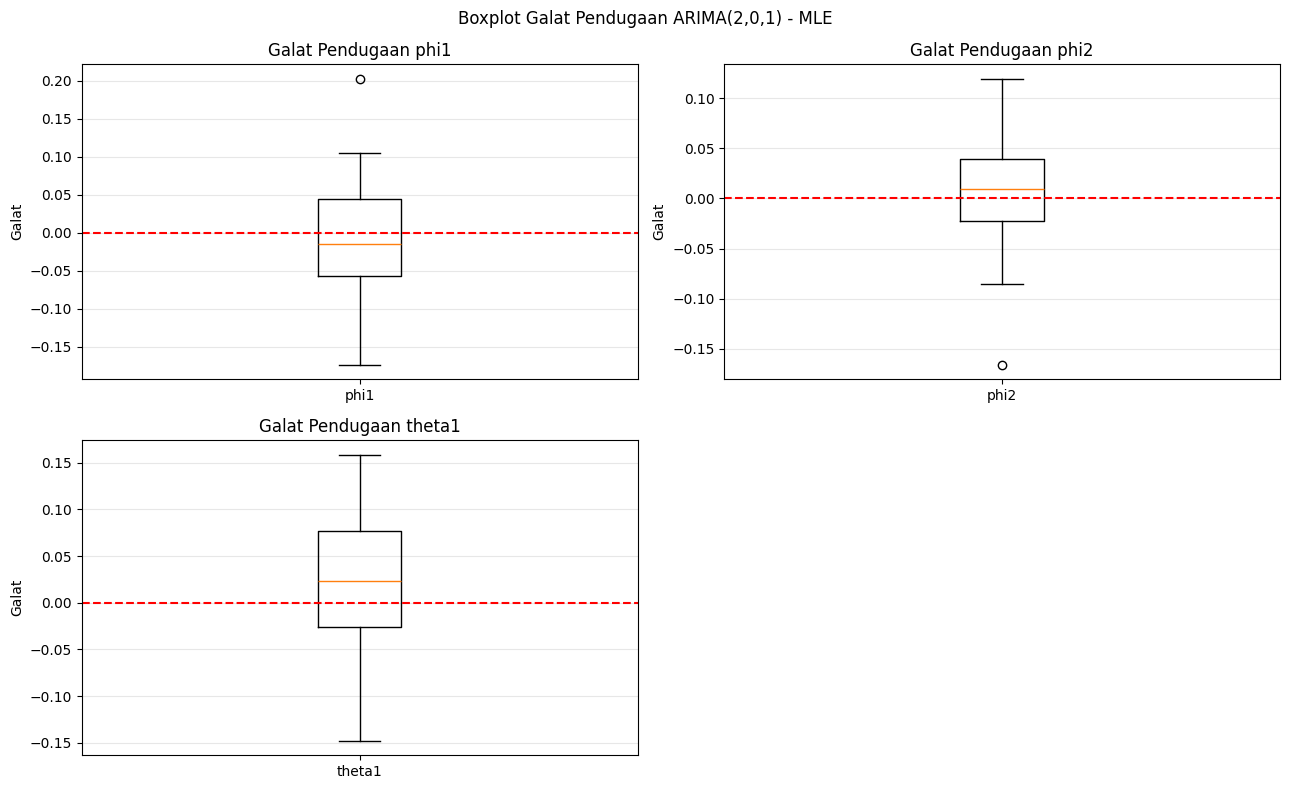

In [77]:
parameter_plot = ["phi1", "phi2", "theta1"]

nilai_asli_plot = {
    "phi1": phi1_true,
    "phi2": phi2_true,
    "theta1": theta1_true
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes = axes.flatten()

for ax, parameter in zip(axes, parameter_plot):
    galat = df_valid[parameter] - nilai_asli_plot[parameter]

    ax.boxplot(galat.dropna(), labels=[parameter])
    ax.axhline(
        0, color="red", linestyle="--",
        label="Galat = 0"
    )
    ax.set_title(f"Galat Pendugaan {parameter}")
    ax.set_ylabel("Galat")
    ax.grid(axis="y", alpha=0.3)

axes[-1].axis("off")

plt.suptitle("Boxplot Galat Pendugaan ARIMA(2,0,1) - MLE")
plt.tight_layout()
plt.show()

##  ARIMA(2,0,1) - Metode Kuadrat Terkecil

Dari 30 hasil dugaan untuk setiap parameter, dihitung bias dan ragam penduga.

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# ============================================================
# PENGATURAN SIMULASI
# ============================================================

n = 500
R = 30
sigma = 1.0

# Parameter sebenarnya ARIMA(2,0,1)
true_201 = {
    "c": 2.0,
    "phi1": 0.5,
    "phi2": -0.25,
    "theta1": 0.4
}

# Generator bilangan acak
rng = np.random.default_rng()


# ============================================================
# FUNGSI RESIDUAL CLS ARIMA(2,0,1)
# ============================================================

def residuals_cls_201(params, y):
    c, phi1, phi2, theta1 = params
    residual = np.zeros(len(y))

    for t in range(2, len(y)):
        residual[t] = (
            y[t]
            - c
            - phi1 * y[t-1]
            - phi2 * y[t-2]
            - theta1 * residual[t-1]
        )

    return residual[2:]


# ============================================================
# SIMULASI DAN ESTIMASI CLS SELAMA 30 ULANGAN
# ============================================================

hasil_201 = []
status_optimasi = []

for r in range(R):

    # Simulasi dataset baru
    eps = rng.normal(0, sigma, n)
    y_sim = np.zeros(n)

    for t in range(2, n):
        y_sim[t] = (
            true_201["c"]
            + true_201["phi1"] * y_sim[t-1]
            + true_201["phi2"] * y_sim[t-2]
            + eps[t]
            + true_201["theta1"] * eps[t-1]
        )

    # Estimasi parameter menggunakan CLS
    hasil = least_squares(
        residuals_cls_201,
        x0=[np.mean(y_sim) * 0.5, 0.1, 0.1, 0.1],
        args=(y_sim,)
    )

    hasil_201.append(hasil.x)
    status_optimasi.append(hasil.success)

# Tabel hasil pendugaan
df_201 = pd.DataFrame(
    hasil_201,
    columns=["c", "phi1", "phi2", "theta1"]
)

df_201.insert(0, "Ulangan", np.arange(1, R + 1))
df_201["Optimasi berhasil"] = status_optimasi

print("Hasil Pendugaan CLS ARIMA(2,0,1)")
print("Jumlah optimasi berhasil:",
      sum(status_optimasi), "dari", R)

display(df_201.round(4))

Hasil Pendugaan CLS ARIMA(2,0,1)
Jumlah optimasi berhasil: 30 dari 30


,Ulangan,c,phi1,phi2,theta1,Optimasi berhasil
0,1,1.7605,0.5725,-0.2212,0.3522,True
1,2,1.9372,0.5378,-0.2362,0.3302,True
2,3,2.1003,0.4223,-0.2190,0.4507,True
3,4,2.0984,0.3719,-0.1502,0.4363,True
4,5,2.1743,0.4780,-0.2797,0.4152,True
5,6,1.9203,0.5811,-0.2828,0.3521,True
6,7,1.7128,0.5314,-0.2152,0.3172,True
7,8,1.8198,0.5077,-0.2451,0.4016,True
8,9,2.0188,0.4758,-0.1937,0.4274,True
9,10,1.9045,0.5465,-0.2562,0.4021,True


In [79]:
# ============================================================
# RINGKASAN BIAS DAN RAGAM CLS ARIMA(2,0,1)
# ============================================================

df_valid_201 = df_201.loc[
    df_201["Optimasi berhasil"]
].copy()

ringkasan_201 = []

for parameter, nilai_asli in true_201.items():
    penduga = df_valid_201[parameter].dropna()

    ringkasan_201.append({
        "Parameter": parameter,
        "Parameter Sebenarnya": nilai_asli,
        "Jumlah Estimasi": len(penduga),
        "Rata-rata Dugaan": penduga.mean(),
        "Bias": penduga.mean() - nilai_asli,
        "Ragam": penduga.var(ddof=1)
    })

tabel_bias_ragam_201 = pd.DataFrame(ringkasan_201)

print("Ringkasan Bias dan Ragam CLS ARIMA(2,0,1)")
display(tabel_bias_ragam_201.round(5))

Ringkasan Bias dan Ragam CLS ARIMA(2,0,1)


,Parameter,Parameter Sebenarnya,Jumlah Estimasi,Rata-rata Dugaan,Bias,Ragam
0,c,2.00,30,2.02896,0.02896,0.02183
1,phi1,0.50,30,0.49617,-0.00383,0.00901
2,phi2,-0.25,30,-0.25772,-0.00772,0.00512
3,theta1,0.40,30,0.39122,-0.00878,0.00928


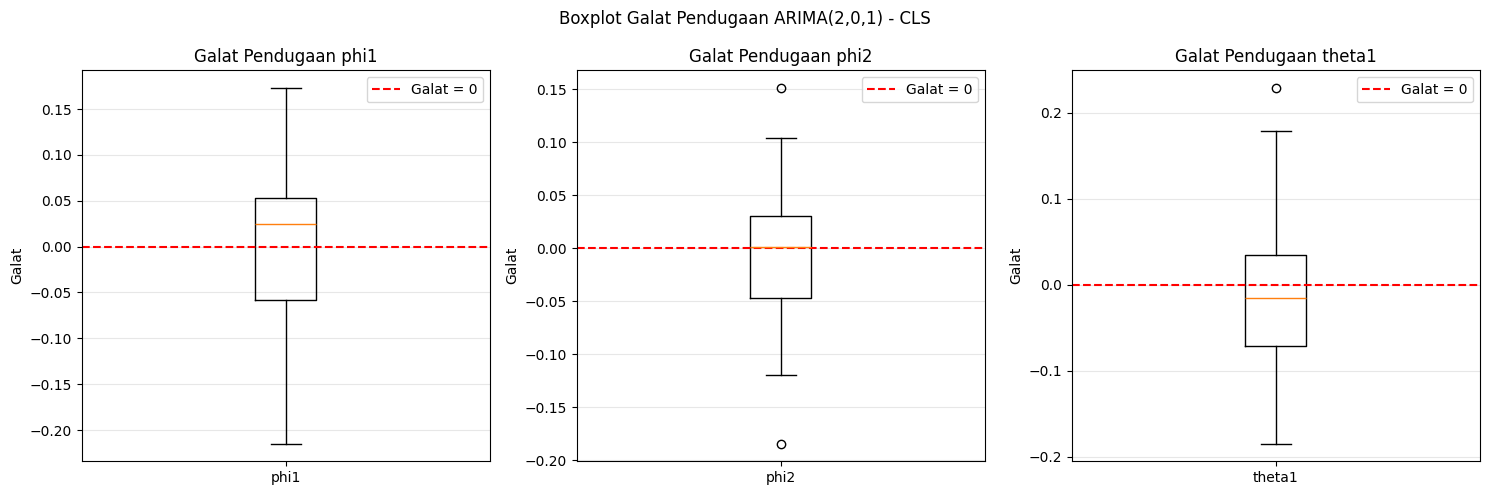

In [80]:
# ============================================================
# BOXPLOT GALAT PENDUGAAN CLS ARIMA(2,0,1)
# Tanpa parameter c
# ============================================================

parameter_plot = ["phi1", "phi2", "theta1"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, parameter in zip(axes, parameter_plot):

    galat = (
        df_valid_201[parameter] - true_201[parameter]
    ).dropna()

    ax.boxplot(galat, labels=[parameter])
    ax.axhline(
        0,
        color="red",
        linestyle="--",
        label="Galat = 0"
    )

    ax.set_title(f"Galat Pendugaan {parameter}")
    ax.set_ylabel("Galat")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

plt.suptitle("Boxplot Galat Pendugaan ARIMA(2,0,1) - CLS")
plt.tight_layout()
plt.show()

## ARIMA(2,0,1) - Perbandingan Bias dan Ragam MLE VS MKT (CLS)
ARIMA(2,0,1) - 30 ULANGAN

In [81]:
df_mle_banding = df_valid.copy()

df_mle_banding["c_model"] = (
    df_mle_banding["c"]
    * (1 - df_mle_banding["phi1"]
       - df_mle_banding["phi2"])
)

# Kolom parameter yang akan dibandingkan
kolom_mle = {
    "c": "c_model",
    "phi1": "phi1",
    "phi2": "phi2",
    "theta1": "theta1"
}

hasil_perbandingan = []

for parameter, nilai_asli in true_201.items():

    # Hasil estimasi MLE
    dugaan_mle = (
        df_mle_banding[kolom_mle[parameter]]
        .dropna()
    )

    # Hasil estimasi MKT/CLS
    dugaan_mkt = (
        df_valid_201[parameter]
        .dropna()
    )

    hasil_perbandingan.append({
        "Parameter": parameter,
        "Nilai Asli": nilai_asli,

        "Rata-rata MLE": dugaan_mle.mean(),
        "Bias MLE": dugaan_mle.mean() - nilai_asli,
        "Ragam MLE": dugaan_mle.var(ddof=1),

        "Rata-rata MKT (CLS)": dugaan_mkt.mean(),
        "Bias MKT (CLS)": dugaan_mkt.mean() - nilai_asli,
        "Ragam MKT (CLS)": dugaan_mkt.var(ddof=1)
    })

tabel_perbandingan = pd.DataFrame(hasil_perbandingan)

print("Perbandingan Bias dan Ragam MLE vs MKT")
display(tabel_perbandingan.round(5))


Perbandingan Bias dan Ragam MLE vs MKT


,Parameter,Nilai Asli,Rata-rata MLE,Bias MLE,Ragam MLE,Rata-rata MKT (CLS),Bias MKT (CLS),Ragam MKT (CLS)
0,c,2.00,1.98493,-0.01507,0.02861,2.02896,0.02896,0.02183
1,phi1,0.50,0.49299,-0.00701,0.00714,0.49617,-0.00383,0.00901
2,phi2,-0.25,-0.24336,0.00664,0.00367,-0.25772,-0.00772,0.00512
3,theta1,0.40,0.42160,0.02160,0.00619,0.39122,-0.00878,0.00928


**Interpretasi Bias Penduga**

Bias penduga digunakan untuk melihat kecenderungan hasil estimasi terhadap parameter sebenarnya. Bias positif menunjukkan bahwa hasil pendugaan cenderung lebih tinggi daripada nilai sebenarnya, sedangkan bias negatif menunjukkan kecenderungan pendugaan yang lebih rendah. Semakin dekat bias dengan nol, semakin kecil penyimpangan rata-rata hasil pendugaan terhadap parameter sebenarnya.

Perbandingan bias MLE dan MKT dilakukan untuk setiap parameter karena kedua metode belum tentu menghasilkan kinerja yang sama. Metode dengan nilai absolut bias lebih kecil menunjukkan kecenderungan pendugaan yang lebih dekat dengan nilai parameter sebenarnya secara rata-rata.

**Interpretasi Ragam Penduga**

Ragam penduga menggambarkan variasi hasil estimasi selama 30 kali ulangan. Ragam yang lebih kecil menunjukkan bahwa hasil pendugaan cenderung lebih konsisten antarulangan. Sebaliknya, ragam yang lebih besar menunjukkan bahwa hasil pendugaan lebih bervariasi.

Perbandingan ragam MLE dan MKT dilakukan untuk melihat presisi masing-masing metode pada setiap parameter. Namun, ragam yang lebih kecil tidak selalu berarti metode tersebut menghasilkan pendugaan yang lebih baik karena bias juga perlu diperhatikan. Oleh karena itu, penilaian terhadap kedua metode dilakukan dengan mempertimbangkan bias dan ragam secara bersamaan.

## ARIMA(2,0,1) - Boxplot perbandingan Metode Kuadrat Terkecil vs Metode Kemungkinan Maksimum

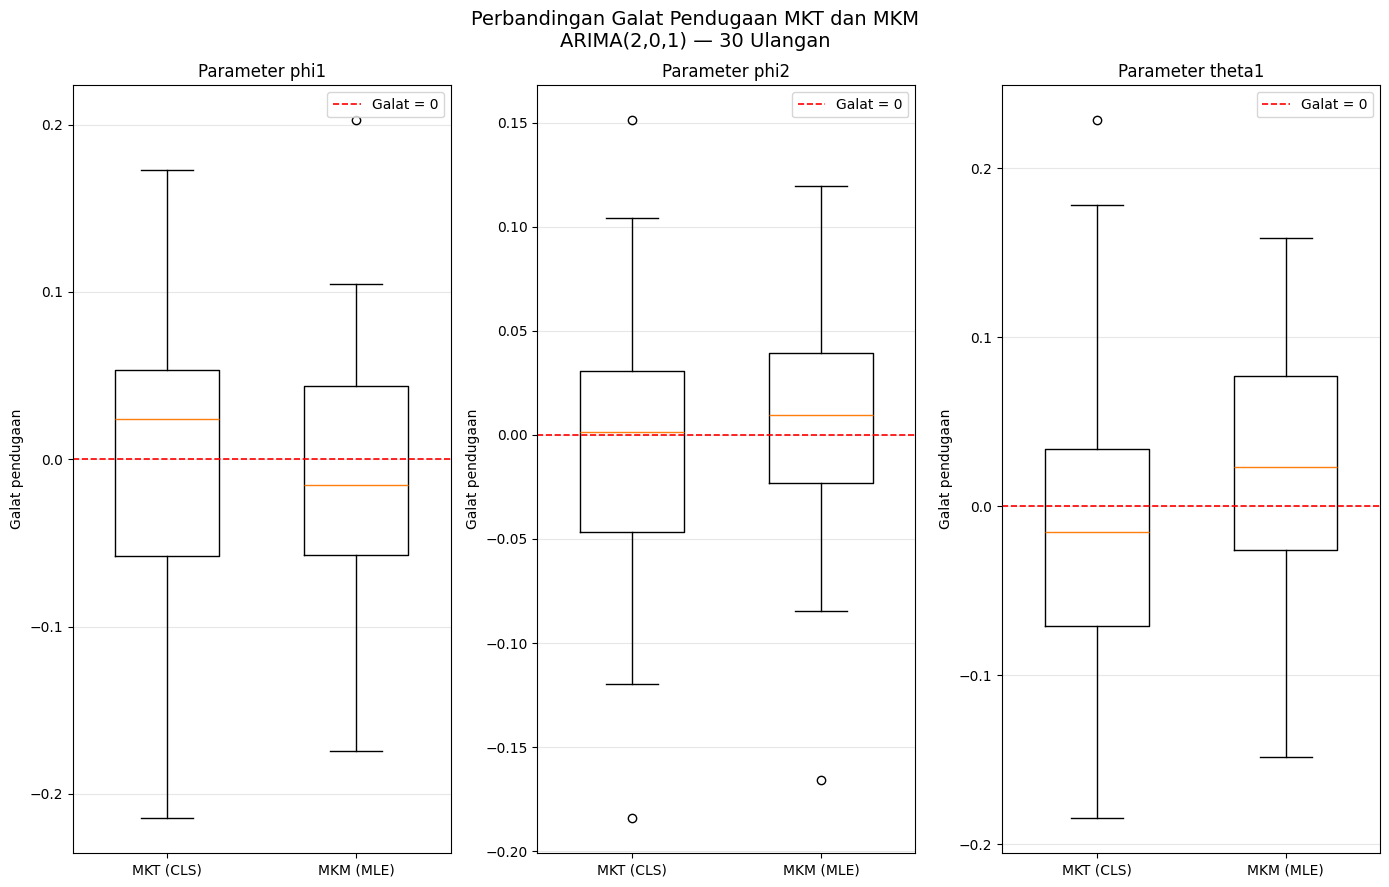

In [82]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# BOXPLOT PERBANDINGAN GALAT PENDUGAAN MKT DAN MKM
# Model ARIMA(2,0,1)
# ============================================================

# Parameter yang diestimasi oleh kedua metode
parameter_plot = ["phi1", "phi2", "theta1"]

# Nilai parameter sebenarnya
nilai_asli = {
    "phi1": 0.5,
    "phi2": -0.25,
    "theta1": 0.4
}

# Data hasil estimasi:
# MKT/CLS : df_valid_201
# MKM/MLE : df_valid

fig, axes = plt.subplots(1, 3, figsize=(14, 9))
axes = axes.flatten()

for ax, parameter in zip(axes, parameter_plot):

    # Galat pendugaan MKT
    galat_mkt = (
        df_valid_201[parameter] - nilai_asli[parameter]
    ).dropna()

    # Galat pendugaan MKM
    galat_mkm = (
        df_valid[parameter] - nilai_asli[parameter]
    ).dropna()

    # Dua boxplot berdampingan
    ax.boxplot(
        [galat_mkt, galat_mkm],
        positions=[1, 2],
        widths=0.55,
        labels=["MKT (CLS)", "MKM (MLE)"]
    )

    # Garis referensi galat nol
    ax.axhline(
        0,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label="Galat = 0"
    )

    ax.set_title(f"Parameter {parameter}")
    ax.set_ylabel("Galat pendugaan")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

plt.suptitle(
    "Perbandingan Galat Pendugaan MKT dan MKM\n"
    "ARIMA(2,0,1) — 30 Ulangan",
    fontsize=14
)

plt.tight_layout()
plt.show()


**Parameter $(\phi_1)$**

Kedua metode menghasilkan median galat yang relatif dekat dengan nol. Median galat MLE sedikit lebih dekat ke nol dibandingkan MKT. Sebaran bagian tengah kedua boxplot juga relatif mirip, dengan kotak MLE sedikit lebih sempit. Namun, MLE memiliki pencilan positif yang lebih jauh dari nol. Dengan demikian, karakteristik sebaran galat kedua metode relatif serupa, meskipun terdapat perbedaan pada pencilan.

**Parameter $(\phi_2)$**

Median galat MKT berada lebih dekat dengan nol dibandingkan MLE. Namun, kotak MLE terlihat lebih sempit, yang menunjukkan bahwa sebaran galat pada bagian tengah distribusinya lebih kecil. MKT juga memiliki pencilan positif yang lebih jauh dari nol. Hal ini menunjukkan bahwa kedekatan median dengan nol dan lebar sebaran galat tidak selalu memberikan kesimpulan yang sama.

**Parameter $(\theta_1)$**

Median galat MKT lebih dekat dengan nol dibandingkan MLE. Sebaran bagian tengah kedua metode relatif mirip, meskipun kotak MLE sedikit lebih sempit. Sementara itu, MKT memiliki pencilan yang lebih ekstrem pada sisi positif maupun negatif. Secara visual, MLE menunjukkan sebaran bagian tengah yang sedikit lebih sempit, sedangkan MKT memiliki beberapa hasil pendugaan dengan galat yang lebih jauh dari nol.

### Kesimpulan Perbandingan MLE dan MKT pada ARIMA(2,0,1)

Berdasarkan tabel perbandingan bias dan ragam, karakteristik pendugaan MLE dan MKT berbeda menurut parameter yang diamati. Pada parameter $(\phi_1)$, MKT memiliki bias absolut yang lebih kecil, sementara ragam MLE lebih kecil. Untuk parameter $(\phi_2)$, MLE menghasilkan bias absolut dan ragam yang lebih kecil dibandingkan MKT. Sementara itu, pada parameter $(\theta_1)$, MKT memiliki bias absolut yang lebih kecil, tetapi MLE menghasilkan ragam yang lebih kecil.

Hasil tersebut menunjukkan bahwa tidak ada satu metode yang selalu unggul dalam seluruh aspek pendugaan. MLE cenderung menghasilkan ragam yang lebih kecil pada ketiga parameter AR dan MA, sedangkan metode dengan bias absolut terkecil berbeda menurut parameternya. Oleh karena itu, perbandingan kedua metode perlu mempertimbangkan bias dan ragam secara bersamaan.

## ARIMA(1,1,1) - Metode Kuadrat Terkecil

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# ============================================================
# PENGATURAN SIMULASI
# ============================================================

n = 500
R = 30
sigma = 1.0

# Parameter sebenarnya ARIMA(1,1,1)
true_111 = {
    "c": 0.2,
    "phi": 0.6,
    "theta": 0.4
}

# Generator bilangan acak
rng = np.random.default_rng()

# Simpan data hasil differencing untuk dipakai oleh MKT dan MLE
# Setiap kolom adalah satu dataset simulasi.
W_111 = np.zeros((n - 1, R))


# ============================================================
# FUNGSI RESIDUAL CLS ARIMA(1,1,1)
# ============================================================

def residuals_cls_111(params, w):
    c, phi, theta = params
    residual = np.zeros(len(w))

    for t in range(1, len(w)):
        residual[t] = (
            w[t]
            - c
            - phi * w[t-1]
            - theta * residual[t-1]
        )

    return residual[1:]


# ============================================================
# SIMULASI DAN ESTIMASI CLS SELAMA 30 ULANGAN
# ============================================================

hasil_111 = []
status_optimasi_111 = []

for r in range(R):

    # Simulasi data ARIMA(1,1,1)
    eps = rng.normal(0, sigma, n)
    w_sim = np.zeros(n)

    # w_sim merupakan data hasil differencing
    for t in range(1, n):
        w_sim[t] = (
            true_111["c"]
            + true_111["phi"] * w_sim[t-1]
            + eps[t]
            + true_111["theta"] * eps[t-1]
        )

    # Data asli diperoleh melalui cumulative sum
    y_sim = np.cumsum(w_sim)

    # Differencing data asli untuk estimasi
    w = np.diff(y_sim)

    # Simpan dataset yang sama agar dapat digunakan oleh MLE di R
    W_111[:, r] = w

    # Estimasi parameter CLS
    hasil = least_squares(
        residuals_cls_111,
        x0=[0.1, 0.3, 0.2],
        args=(w,)
    )

    hasil_111.append(hasil.x)
    status_optimasi_111.append(hasil.success)


# ============================================================
# TABEL HASIL PENDUGAAN
# ============================================================

df_111 = pd.DataFrame(
    hasil_111,
    columns=["c", "phi", "theta"]
)

df_111.insert(0, "Ulangan", np.arange(1, R + 1))
df_111["Optimasi berhasil"] = status_optimasi_111

print("Hasil Pendugaan CLS ARIMA(1,1,1)")
print(
    "Jumlah optimasi berhasil:",
    sum(status_optimasi_111),
    "dari",
    R
)

display(df_111.round(4))


Hasil Pendugaan CLS ARIMA(1,1,1)
Jumlah optimasi berhasil: 30 dari 30


,Ulangan,c,phi,theta,Optimasi berhasil
0,1,0.1582,0.6085,0.3742,True
1,2,0.2506,0.5693,0.3843,True
2,3,0.0602,0.5903,0.4559,True
3,4,0.2721,0.6100,0.3343,True
4,5,0.1714,0.5788,0.3807,True
5,6,0.1133,0.6169,0.3640,True
6,7,0.2694,0.4741,0.5114,True
7,8,0.2455,0.6034,0.3863,True
8,9,0.1060,0.6075,0.4098,True
9,10,0.0790,0.6355,0.3705,True


In [84]:
# ============================================================
# RINGKASAN BIAS DAN RAGAM CLS ARIMA(1,1,1)
# ============================================================

df_valid_111 = df_111.loc[
    df_111["Optimasi berhasil"]
].copy()

ringkasan_111 = []

for parameter, nilai_asli in true_111.items():
    penduga = df_valid_111[parameter].dropna()

    ringkasan_111.append({
        "Parameter": parameter,
        "Parameter Sebenarnya": nilai_asli,
        "Jumlah Estimasi": len(penduga),
        "Rata-rata Dugaan": penduga.mean(),
        "Bias": penduga.mean() - nilai_asli,
        "Ragam": penduga.var(ddof=1)
    })

tabel_bias_ragam_111 = pd.DataFrame(ringkasan_111)

print("Ringkasan Bias dan Ragam CLS ARIMA(1,1,1)")
display(tabel_bias_ragam_111.round(5))

Ringkasan Bias dan Ragam CLS ARIMA(1,1,1)


,Parameter,Parameter Sebenarnya,Jumlah Estimasi,Rata-rata Dugaan,Bias,Ragam
0,c,0.2,30,0.20673,0.00673,0.00758
1,phi,0.6,30,0.58910,-0.01090,0.00114
2,theta,0.4,30,0.40634,0.00634,0.00164


## ARIMA(1,1,1) - Metode Kemungkinan Maksimum

Pada bagian ini, MLE diterapkan pada 30 dataset hasil differencing yang sama dengan dataset yang digunakan pada estimasi MKT/CLS. Dengan demikian, perbandingan kedua metode tidak tercampur oleh perbedaan realisasi data simulasi.


In [85]:
%%R

# ============================================================
# NOMOR 2: MLE ARIMA(1,1,1) - 30 ULANGAN
# MLE diestimasi pada data hasil differencing (ARMA(1,1))
# Menggunakan dataset yang sama dengan MKT/CLS
# ============================================================

W_111 <- as.matrix(W_111)
n <- nrow(W_111)
R <- ncol(W_111)

# Parameter sebenarnya
c_asli <- 0.2
phi_asli <- 0.6
theta_asli <- 0.4
sigma <- 1
sigma2 <- sigma^2

cat("Model: ARIMA(1,1,1) melalui ARMA(1,1) pada data differencing\n")
cat("Jumlah observasi per dataset:", n, "\n")
cat("Jumlah ulangan:", R, "\n")
cat("Data MLE sama dengan data MKT/CLS: ya\n\n")

# ============================================================
# 1. MENYIAPKAN TEMPAT PENYIMPANAN HASIL
# ============================================================

c_dugaan <- rep(NA_real_, R)
phi_dugaan <- rep(NA_real_, R)
theta_dugaan <- rep(NA_real_, R)
sigma2_dugaan <- rep(NA_real_, R)
konvergen <- rep(FALSE, R)

# ============================================================
# 2. ESTIMASI MLE UNTUK SETIAP DATASET
# ============================================================

for (i in seq_len(R)) {

  # Gunakan dataset hasil differencing yang sama dengan CLS
  w <- as.numeric(W_111[, i])

  model <- tryCatch(
    arima(
      w,
      order = c(1, 0, 1),
      method = "ML",
      include.mean = TRUE,
      transform.pars = TRUE
    ),
    error = function(e) {
      message("Ulangan ", i, " gagal: ", conditionMessage(e))
      NULL
    }
  )

  if (is.null(model)) {
    next
  }

  # Simpan penduga parameter AR dan MA
  phi_dugaan[i] <- unname(model$coef["ar1"])
  theta_dugaan[i] <- unname(model$coef["ma1"])

  # Pada ARMA(1,1), R mengestimasi mean proses (mu).
  # Konversikan ke konstanta rekursif c = mu * (1 - phi).
  mu_dugaan <- unname(model$coef["intercept"])
  c_dugaan[i] <- mu_dugaan * (1 - phi_dugaan[i])

  # Penduga varians inovasi
  sigma2_dugaan[i] <- model$sigma2

  # Kode konvergensi 0 menunjukkan optimizer berhasil
  konvergen[i] <- isTRUE(model$code == 0)
}

# ============================================================
# 3. TABEL HASIL ESTIMASI 30 ULANGAN
# ============================================================

hasil_30 <- data.frame(
  Ulangan = seq_len(R),
  C_MLE = c_dugaan,
  Phi_MLE = phi_dugaan,
  Theta_MLE = theta_dugaan,
  Sigma2_MLE = sigma2_dugaan,
  Konvergen = konvergen
)

cat("\nJumlah estimasi yang konvergen:",
    sum(hasil_30$Konvergen), "dari", R, "\n\n")
print(hasil_30, row.names = FALSE)

# ============================================================
# 4. MENGHITUNG BIAS DAN RAGAM
# ============================================================

kolom_parameter <- c("C_MLE", "Phi_MLE", "Theta_MLE", "Sigma2_MLE")
hasil_valid <- hasil_30[
  hasil_30$Konvergen &
    complete.cases(hasil_30[, kolom_parameter]),
  kolom_parameter
]

if (nrow(hasil_valid) == 0) {
  stop("Tidak ada estimasi yang konvergen. Periksa hasil optimasi.")
}

nilai_asli <- c(c_asli, phi_asli, theta_asli, sigma2)

rata_dugaan <- c(
  mean(hasil_valid$C_MLE),
  mean(hasil_valid$Phi_MLE),
  mean(hasil_valid$Theta_MLE),
  mean(hasil_valid$Sigma2_MLE)
)

ragam <- c(
  var(hasil_valid$C_MLE),
  var(hasil_valid$Phi_MLE),
  var(hasil_valid$Theta_MLE),
  var(hasil_valid$Sigma2_MLE)
)

bias <- rata_dugaan - nilai_asli

ringkasan_MLE <- data.frame(
  Parameter = c("c", "Phi (AR1)", "Theta (MA1)", "Sigma2"),
  Nilai_Asli = nilai_asli,
  Rata_Rata_Dugaan = rata_dugaan,
  Bias = bias,
  Ragam = ragam
)

cat("\nRingkasan Bias dan Ragam MLE ARIMA(1,1,1)\n")
print(ringkasan_MLE, row.names = FALSE)


Model: ARIMA(1,1,1) melalui ARMA(1,1) pada data differencing
Jumlah observasi per dataset: 499 
Jumlah ulangan: 30 
Data MLE sama dengan data MKT/CLS: ya


Jumlah estimasi yang konvergen: 30 dari 30 

 Ulangan      C_MLE   Phi_MLE Theta_MLE Sigma2_MLE Konvergen
       1 0.15672577 0.6074377 0.3734626  1.0204157      TRUE
       2 0.24278168 0.5705689 0.3829568  1.0407610      TRUE
       3 0.06251370 0.5892538 0.4551207  0.9588850      TRUE
       4 0.26206310 0.6123806 0.3323938  1.0435202      TRUE
       5 0.16851638 0.5768896 0.3824579  1.0263260      TRUE
       6 0.11691604 0.6140517 0.3671282  1.0216153      TRUE
       7 0.26319784 0.4734766 0.5123306  0.9603606      TRUE
       8 0.24225935 0.6028756 0.3852447  1.0027027      TRUE
       9 0.11043419 0.5982582 0.4247456  1.0665498      TRUE
      10 0.08297207 0.6336249 0.3719277  0.9400885      TRUE
      11 0.02859808 0.5799979 0.3853992  0.9674639      TRUE
      12 0.23946712 0.6036290 0.3804696  0.9589300      TRUE
      

## ARIMA(1,1,1) - Perbandingan Bias dan Ragam MLE VS MKT (CLS)

In [86]:
import pandas as pd

# ============================================================
# PERBANDINGAN BIAS DAN RAGAM MLE VS MKT (CLS)
# ARIMA(1,1,1) - 30 ULANGAN
# ============================================================

# Ringkasan MLE dari R
tabel_mle_111 = pd.DataFrame(ringkasan_MLE).copy()

tabel_mle_111["Parameter"] = (
    tabel_mle_111["Parameter"].replace({
        "Phi (AR1)": "phi",
        "Theta (MA1)": "theta",
        "Sigma2": "sigma2"
    })
)

tabel_mle_111 = tabel_mle_111.rename(columns={
    "Nilai_Asli": "Nilai Asli",
    "Rata_Rata_Dugaan": "Rata-rata Dugaan MLE",
    "Bias": "Bias MLE",
    "Ragam": "Ragam MLE"
})

# Ringkasan CLS dari Python
tabel_cls_111 = tabel_bias_ragam_111[
    ["Parameter", "Parameter Sebenarnya",
     "Rata-rata Dugaan", "Bias", "Ragam"]
].copy()

tabel_cls_111["Parameter"] = (
    tabel_cls_111["Parameter"].astype(str).str.lower().str.strip()
)

tabel_cls_111 = tabel_cls_111.rename(columns={
    "Parameter Sebenarnya": "Nilai Asli CLS",
    "Rata-rata Dugaan": "Rata-rata Dugaan CLS",
    "Bias": "Bias CLS",
    "Ragam": "Ragam CLS"
})

# Gabungkan hasil berdasarkan parameter
tabel_perbandingan_111 = pd.merge(
    tabel_mle_111[
        ["Parameter", "Nilai Asli", "Rata-rata Dugaan MLE",
         "Bias MLE", "Ragam MLE"]
    ],
    tabel_cls_111[
        ["Parameter", "Rata-rata Dugaan CLS", "Bias CLS", "Ragam CLS"]
    ],
    on="Parameter",
    how="inner"
)

# Bandingkan parameter yang diduga oleh kedua metode.
# Sigma^2 hanya ditampilkan pada ringkasan MLE karena kode CLS saat ini
# tidak menyimpan sigma^2 sebagai parameter yang diestimasi.
tabel_perbandingan_111 = tabel_perbandingan_111[
    tabel_perbandingan_111["Parameter"].isin(["c", "phi", "theta"])
]

tabel_perbandingan_111 = tabel_perbandingan_111[
    [
        "Parameter", "Nilai Asli",
        "Rata-rata Dugaan MLE", "Rata-rata Dugaan CLS",
        "Bias MLE", "Bias CLS",
        "Ragam MLE", "Ragam CLS"
    ]
]

display(tabel_perbandingan_111.round(5))


,Parameter,Nilai Asli,Rata-rata Dugaan MLE,Rata-rata Dugaan CLS,Bias MLE,Bias CLS,Ragam MLE,Ragam CLS
0,c,0.2,0.20606,0.20673,0.00606,0.00673,0.00732,0.00758
1,phi,0.6,0.58788,0.58910,-0.01212,-0.01090,0.00111,0.00114
2,theta,0.4,0.40687,0.40634,0.00687,0.00634,0.00164,0.00164


Berdasarkan tabel perbandingan, kedekatan rata-rata penduga terhadap parameter sebenarnya dapat dinilai melalui nilai absolut bias: semakin kecil nilai absolut bias, semakin dekat rata-rata pendugaan dengan nilai sebenarnya. Ragam digunakan untuk melihat konsistensi hasil estimasi antarulangan; ragam yang lebih kecil menunjukkan variasi pendugaan yang lebih rendah. Perbandingan dilakukan untuk setiap parameter ($c$, $\phi$, dan $\theta$), karena keunggulan suatu metode dapat berbeda antarparameter. Nilai $\sigma^2$ ditampilkan pada ringkasan MLE secara terpisah karena kode CLS pada bagian ini belum mengestimasi varians inovasi sebagai parameter tersendiri.


## ARIMA(1,1,1) - Boxplot Perbandingan Galat Pendugaan MKT dan MKM


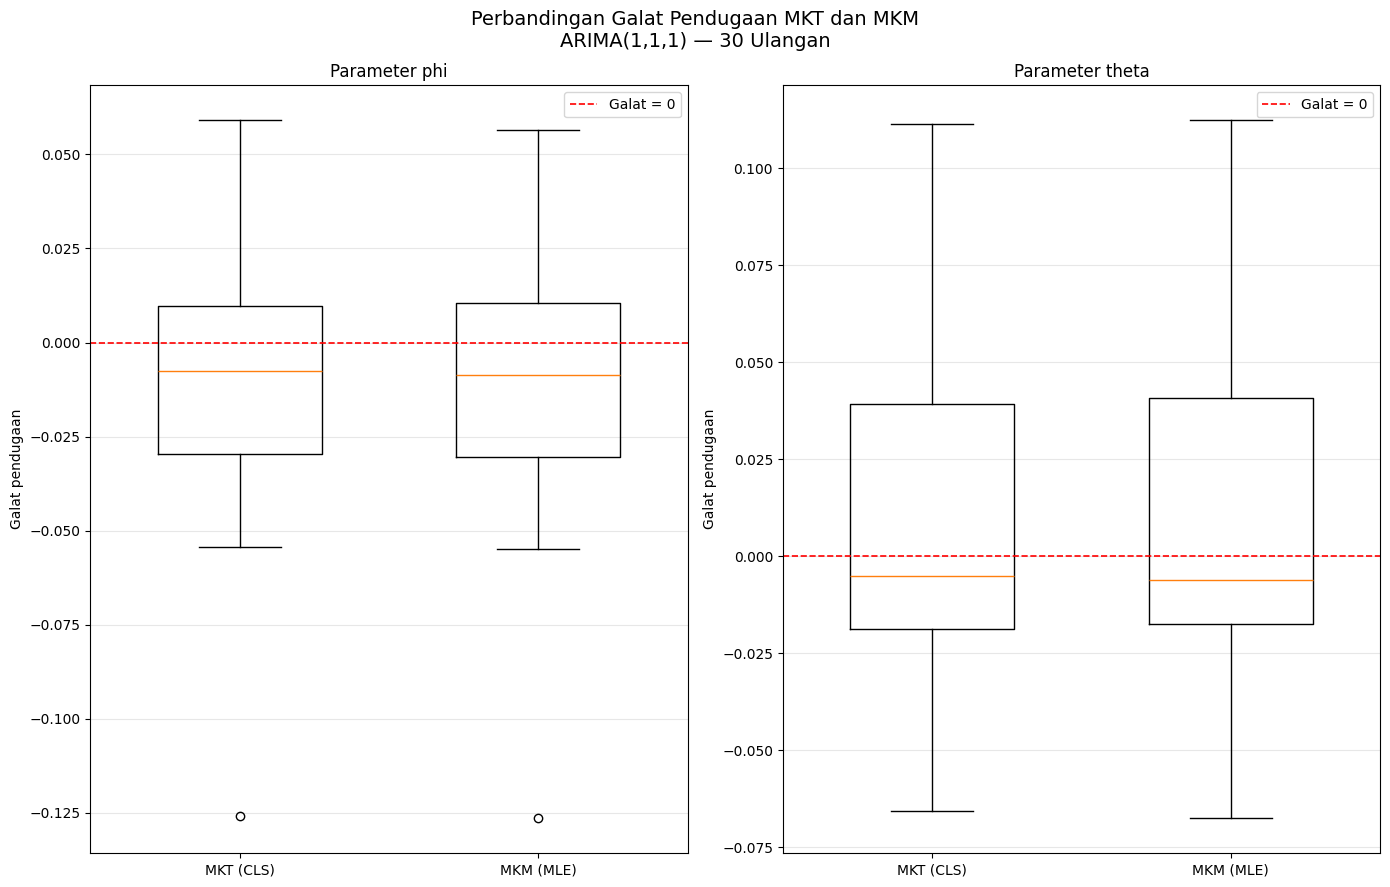

In [87]:
# ============================================================
# BOXPLOT PERBANDINGAN GALAT MKT/CLS DAN MKM/MLE
# ARIMA(1,1,1) - Parameter c, phi, theta
# ============================================================

# Pastikan hanya hasil MLE yang konvergen digunakan
konv = hasil_30["Konvergen"]
if konv.dtype == object:
    konv = konv.astype(str).str.upper().isin(["TRUE", "T", "1"])
else:
    konv = konv.fillna(False).astype(bool)

hasil_mle_valid_py = hasil_30.loc[konv].copy()

parameter_plot_111 = [
    ("phi", "Phi_MLE", "phi"),
    ("theta", "Theta_MLE", "theta")
]

nilai_asli_111 = {"c": 0.2, "phi": 0.6, "theta": 0.4}

fig, axes = plt.subplots(1, 2, figsize=(14, 9))

for ax, (parameter, kolom_mle, kolom_cls) in zip(axes, parameter_plot_111):

    galat_cls = (
        df_valid_111[kolom_cls] - nilai_asli_111[parameter]
    ).dropna()

    galat_mle = (
        hasil_mle_valid_py[kolom_mle] - nilai_asli_111[parameter]
    ).dropna()

    ax.boxplot(
        [galat_cls, galat_mle],
        labels=["MKT (CLS)", "MKM (MLE)"],
        widths=0.55
    )

    ax.axhline(0, color="red", linestyle="--", linewidth=1.2,
               label="Galat = 0")
    ax.set_title(f"Parameter {parameter}")
    ax.set_ylabel("Galat pendugaan")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

plt.suptitle(
    "Perbandingan Galat Pendugaan MKT dan MKM\n"
    "ARIMA(1,1,1) — 30 Ulangan",
    fontsize=14
)
plt.tight_layout()
plt.show()


### Interpretasi Boxplot dan Kesimpulan ARIMA(1,1,1)


Pada boxplot gabungan, galat pendugaan dihitung sebagai nilai penduga dikurangi parameter sebenarnya. Garis horizontal pada nol menunjukkan pendugaan yang tepat. Median yang lebih dekat ke nol menunjukkan galat tipikal yang lebih kecil, sedangkan kotak yang lebih sempit menunjukkan variasi galat pada 50% pengamatan bagian tengah yang lebih rendah. Pencilan menunjukkan ulangan dengan galat yang relatif jauh dibandingkan ulangan lainnya.

Perbandingan dilakukan untuk setiap parameter ($c$, $\phi$, dan $\theta$), karena metode yang memiliki median galat paling dekat ke nol untuk satu parameter belum tentu memiliki sebaran terkecil untuk parameter lainnya. Karena itu, boxplot perlu dibaca bersama tabel bias dan ragam.

Berdasarkan tabel perbandingan, MLE memiliki bias absolut yang lebih kecil pada parameter konstanta \(c\), yaitu 0,00606 dibandingkan 0,00673 pada MKT. Ragam penduga MLE untuk parameter ini juga sedikit lebih kecil. Sebaliknya, pada parameter $(\phi)$ dan $(\theta)$, MKT menghasilkan bias absolut yang lebih kecil dibandingkan MLE. Untuk parameter $(\phi)$, ragam MLE juga sedikit lebih kecil daripada MKT, sedangkan pada parameter $(\theta)$, ragam kedua metode hampir sama. Hasil ini menunjukkan bahwa tidak ada satu metode yang selalu unggul untuk seluruh parameter. Perbandingan bias dan ragam perlu dilakukan secara bersamaan untuk menilai karakteristik pendugaan masing-masing metode pada 30 ulangan simulasi yang digunakan.
